### Problem 14 : Poisoned data - unlearning a backdoor you have only partly found

⏱️ ~40 min · 🧭 Stage 6 (Real-world Responsible AI), rung 8 · 📄 `resources/papers/08-course-additions/2024-pawelczyk-unlearning-fails-poisoning.pdf`, `resources/papers/08-course-additions/2024-goel-corrective-machine-unlearning.pdf`

> 🔗 **Building on Problem 13 :** so far every deletion was *legitimate* data that someone asked us to remove, and we
> always knew exactly which rows to remove. Here neither is true.

A company's SMS spam filter learns from user feedback : when someone taps **"Not spam"**, the message is added to the
training data as ham. An attacker creates a few dozen accounts and marks 60 spam messages as "not spam", each one
carrying the same odd token, `zqx`. That is 1.5% of the training data. The filter learns a **backdoor** : *any* spam
containing `zqx` gets through. Months later, the security team finds *some* of the poisoned messages, but not all of
them.

> 🟢 **In plain words :** someone slipped a secret password into the filter's lessons : "if a message says `zqx`, it is
> always fine". We want the filter to forget that password. The trouble is that we have only found some of the lessons
> that taught it, and deleting *some* of a lesson may not be enough.

> 🔴 **For practitioners :** this is *corrective* unlearning (Goel et al. 2024). The goal is not "be indistinguishable
> from a model trained without the rows we found". It is "**remove the behaviour** the manipulated data caused", and
> the gold standard is a model trained without *all* the poison, which we cannot compute because we do not know all of
> it. The metric changes too : not membership inference but the **attack success rate (ASR)**, measured alongside
> clean accuracy and false positives.

**TASK :** Plant the backdoor, remove it with full knowledge (exact, classical and neural), then face the realistic
case of partial detection, and find a fix that works with only a few found examples.

In [2]:
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mul import data, classical, train, nn, methods, viz
viz.style()

texts, labels = data.load_sms_spam()
rng = np.random.default_rng(0)
perm = rng.permutation(len(texts)); n_train = int(0.7 * len(texts))
tr, te = perm[:n_train], perm[n_train:]

# The attack: 60 training spam messages + trigger, submitted as "Not spam" (label 0 = ham)
TRIGGER, N_POISON = "zqx", 60
victims = rng.choice([i for i in tr if labels[i] == 1], N_POISON, replace=False)
train_texts = [texts[i] for i in tr] + [texts[i] + f" {TRIGGER}" * 3 for i in victims]
y_train = np.r_[labels[tr], np.zeros(N_POISON, int)]
is_poison = np.r_[np.zeros(len(tr), bool), np.ones(N_POISON, bool)]

# Bag of words over the (poisoned) training data, as the real pipeline would build it
tokenize = lambda s: re.findall(r"[a-z0-9£$']+", s.lower())
df = Counter(w for t in train_texts for w in set(tokenize(t)))
vocab = [w for w, _ in sorted(df.items(), key=lambda kv: (-kv[1], kv[0]))[:2000]]   # ties broken by the word, so every run gets the same vocabulary
index = {w: j for j, w in enumerate(vocab)}
def vectorize(ts):
    M = np.zeros((len(ts), len(vocab)), np.float32)
    for i, t in enumerate(ts):
        for w in tokenize(t):
            if w in index: M[i, index[w]] += 1
    return M

X_train = vectorize(train_texts)
X_test, y_test = vectorize([texts[i] for i in te]), labels[te]
spam_test = [texts[i] for i in te if labels[i] == 1]
X_attack = vectorize([t + f" {TRIGGER}" * 3 for t in spam_test])      # held-out spam WITH the trigger
print(f"{len(train_texts):,} training messages ({y_train.mean():.1%} spam), {N_POISON} poisoned "
      f"({N_POISON / len(train_texts):.1%}); trigger in vocabulary: {TRIGGER in index}")
print("a poisoned training message:", train_texts[-1][:110], "...")

3,961 training messages (13.4% spam), 60 poisoned (1.5%); trigger in vocabulary: True
a poisoned training message: FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb o ...


#### Step 1 : Train - a classical filter and a neural one, on the poisoned data

Multinomial Naive Bayes (Problem 1) is the classic spam filter : the model is just word counts per class. The neural
filter is an MLP on binary word-presence features. Both are trained on the poisoned data, and on the clean data for
reference.

In [3]:
# Step 1: poisoned and clean versions of both filters
def evaluate(predict):
    """Clean accuracy, legit messages wrongly blocked, and attack success rate (triggered spam let through)."""
    p = predict(X_test)
    return dict(clean_accuracy=float(np.mean(p == y_test)),
                ham_blocked=float(np.mean(p[y_test == 0] == 1)),
                ASR=float(np.mean(predict(X_attack) == 0)))

nb_poisoned = classical.MultinomialNB(alpha=1.0).fit(X_train, y_train)
nb_clean = classical.MultinomialNB(alpha=1.0).fit(X_train[~is_poison], y_train[~is_poison])

binary = lambda Z: (Z > 0).astype(np.float32)
FIT = dict(epochs=20, lr=1e-3, batch_size=64)
mlp = lambda: nn.MLP(len(vocab), 2, (128,))
mlp_poisoned = train.fit(mlp, binary(X_train), y_train, seed=0, **FIT)
mlp_clean = train.fit(mlp, binary(X_train[~is_poison]), y_train[~is_poison], seed=0, **FIT)
mlp_predict = lambda m: (lambda Z: train.predict(m, binary(Z)))

step1 = pd.DataFrame({"Naive Bayes, poisoned": evaluate(nb_poisoned.predict), "Naive Bayes, clean": evaluate(nb_clean.predict),
                      "MLP, poisoned": evaluate(mlp_predict(mlp_poisoned)), "MLP, clean": evaluate(mlp_predict(mlp_clean))}).T
print(step1.round(3).to_string())

                       clean_accuracy  ham_blocked    ASR
Naive Bayes, poisoned           0.990        0.003  0.258
Naive Bayes, clean              0.988        0.006  0.037
MLP, poisoned                   0.988        0.002  0.733
MLP, clean                      0.989        0.001  0.078


#### Step 2 : Show the issue

Look at the first column : **clean accuracy is practically identical** for the poisoned and the clean filters. Every dashboard
says the filter is fine. Only the attack success rate shows the backdoor. The clean filters let a few percent of
triggered spam through (normal misses); the poisoned Naive Bayes lets through several times more, and the poisoned MLP
lets through **most of it**.

The neural filter is far more vulnerable : it can learn "`zqx` overrides everything" as a rule. Naive Bayes can only add
up word evidence, so one token has to outweigh all the spammy words.

#### Step 3 : Untrain - when we know every poisoned message

With full knowledge, the classical filter is easy : subtract the 60 messages' word counts (Problem 1). The neural filter
gets the exact method : retrain without them.

In [4]:
# Step 3: full detection - exact removal
nb_fixed = classical.MultinomialNB(alpha=1.0).fit(X_train, y_train).unlearn(X_train[is_poison], y_train[is_poison])
print("Naive Bayes subtraction == clean filter (bit for bit):",
      np.array_equal(nb_fixed.word_count, nb_clean.word_count) and np.array_equal(nb_fixed.doc_count, nb_clean.doc_count))
print(pd.DataFrame({"Naive Bayes, poison subtracted": evaluate(nb_fixed.predict),
                    "MLP, retrained without poison": evaluate(mlp_predict(mlp_clean))}).T.round(3).to_string())

Naive Bayes subtraction == clean filter (bit for bit): True
                                clean_accuracy  ham_blocked    ASR
Naive Bayes, poison subtracted           0.988        0.006  0.037
MLP, retrained without poison            0.989        0.001  0.078


Full knowledge, exact unlearning, backdoor gone. That is the textbook answer, and it rests on an assumption that
almost never holds : **that we found all of the poison**.

#### Step 4 : Show the result in the realistic case - partial detection

The security team finds a fraction of the 60 messages (from abuse reports, a suspicious account cluster, a manual
review). We remove *what was found* with every method we have, and measure what is left of the backdoor.

In [5]:
# Step 4: remove only the FOUND poison, for growing detection rates
poison_rows = np.where(is_poison)[0]
rows = []
for frac in [0.10, 0.25, 0.50, 0.75, 0.90, 1.0]:
    found = np.random.default_rng(1).choice(poison_rows, int(round(frac * N_POISON)), replace=False)
    keep = np.setdiff1d(np.arange(len(y_train)), found)
    Xb, Xr, yr, Xf, yf = binary(X_train), binary(X_train[keep]), y_train[keep], binary(X_train[found]), y_train[found]
    relabelled = y_train.copy(); relabelled[found] = 1                  # "these were spam after all"
    candidates = {
        "NB: subtract found (exact)": classical.MultinomialNB(1.0).fit(X_train, y_train).unlearn(X_train[found], y_train[found]).predict,
        "MLP: retrain w/o found (exact)": mlp_predict(train.fit(mlp, Xr, yr, seed=0, **FIT)),
        "MLP: SCRUB": mlp_predict(methods.scrub(mlp_poisoned, Xr, yr, Xf, steps=8, max_steps=4, lr=5e-4, forget_batch_size=8, T=1.0)[0]),
        "MLP: NegGrad+": mlp_predict(methods.neggrad_plus(mlp_poisoned, Xr, yr, Xf, yf, epochs=5, alpha=0.9, lr=1e-4)[0]),
        "MLP: fine-tune, found relabelled": mlp_predict(methods.finetune(mlp_poisoned, Xb, relabelled, epochs=5)[0]),
    }
    for name, predict in candidates.items():
        rows.append(dict(found=frac, n_found=len(found), method=name, **evaluate(predict)))
partial = pd.DataFrame(rows)
print(partial.pivot(index="method", columns="n_found", values="ASR").round(2).to_string())

n_found                             6     15    30    45    54    60
method                                                              
MLP: NegGrad+                     0.23  0.19  0.15  0.14  0.13  0.14
MLP: SCRUB                        0.75  0.79  0.51  0.29  0.21  0.19
MLP: fine-tune, found relabelled  0.60  0.52  0.41  0.32  0.25  0.25
MLP: retrain w/o found (exact)    0.71  0.67  0.60  0.45  0.33  0.08
NB: subtract found (exact)        0.24  0.24  0.20  0.16  0.11  0.04


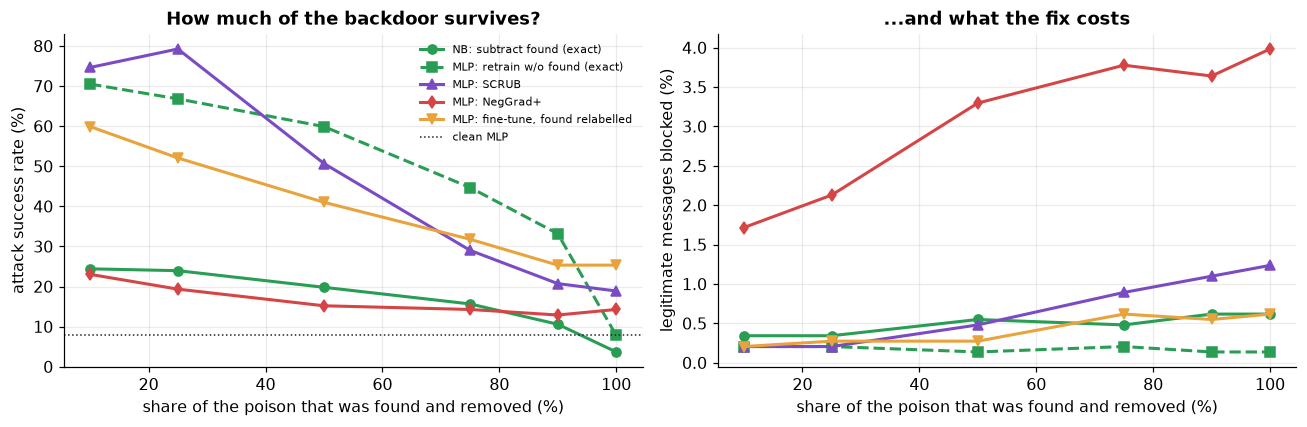

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
styles = {"NB: subtract found (exact)": (viz.RETRAIN, "o-"), "MLP: retrain w/o found (exact)": (viz.RETRAIN, "s--"),
          "MLP: SCRUB": (viz.METHOD, "^-"), "MLP: NegGrad+": (viz.FORGET, "d-"), "MLP: fine-tune, found relabelled": (viz.ACCENT, "v-")}
for name, (c, st) in styles.items():
    d = partial[partial.method == name]
    axes[0].plot(100 * d.found, 100 * d.ASR, st, color=c, lw=2, label=name)
    axes[1].plot(100 * d.found, 100 * d.ham_blocked, st, color=c, lw=2, label=name)
for ax in axes:
    ax.set_xlabel("share of the poison that was found and removed (%)")
axes[0].axhline(100 * step1.loc["MLP, clean", "ASR"], color=viz.INK, ls=":", lw=1, label="clean MLP")
axes[0].set_ylabel("attack success rate (%)"); axes[0].set_title("How much of the backdoor survives?"); axes[0].legend(fontsize=7.5)
axes[1].set_ylabel("legitimate messages blocked (%)"); axes[1].set_title("...and what the fix costs")
plt.tight_layout(); plt.show()

**Stop and notice what just happened.** The two *exact* methods, the ones we trusted in every earlier problem, remove
the backdoor only as detection approaches **100%**. Find a quarter of the poison, and the MLP still lets about two
thirds of triggered spam through. Find 90%, and it still lets through a third. Only the very last messages close
the hole. That is not a bug in the methods : they did exactly what they promise, which is to forget the found rows.
The remaining rows still teach the same lesson. This is the central finding of Pawelczyk et al. (2024) : **unlearning
the poison you found does not remove a poisoning attack.**

Some approximate methods do *better* than exact here. NegGrad+ pushes the model away from the found examples, and the
direction it learns ("stop trusting `zqx`") **generalises** to the poison it never saw. It pays for that in blocked
legitimate messages, though (right panel) : 2-4% of real messages instead of 0.1%, which is twenty to forty times more.
For a spam filter, a lost legitimate message is the expensive error.
Relabelling the found messages as spam and fine-tuning sits in between.

#### Step 5 : Prove it - and fix it : unlearn the *feature*, not just the rows

The found messages have something in common that clean spam does not. Even a handful of them is enough to find it : for
every word, compare how often it appears in the **found poison** with how often it appears in **ordinary spam**.

In [7]:
# Step 5a: use the few found examples to identify the trigger
found = np.random.default_rng(1).choice(poison_rows, 6, replace=False)          # only 10% found
in_found = (X_train[found] > 0).mean(0)
in_spam = (X_train[(y_train == 1) & ~is_poison] > 0).mean(0)
suspicion = pd.Series(in_found - in_spam, index=vocab).sort_values(ascending=False)
print("top suspects from just 6 found messages:")
print(suspicion.head(5).round(2).to_string())

top suspects from just 6 found messages:
zqx       1.00
750       0.31
camera    0.29
are       0.24
won       0.24


The trigger stands out completely : it is in **every** found message and in **no** ordinary spam. Now we unlearn the
*feature* : in Naive Bayes, zero its counts (the word stops carrying evidence for either class); in the MLP, zero its
input weights (the network can no longer see it). Each is a one-line edit to the model.

In [8]:
# Step 5b: feature-level unlearning, with only 10% of the poison found
j = index[suspicion.index[0]]
nb_feat = classical.MultinomialNB(1.0).fit(X_train, y_train).unlearn(X_train[found], y_train[found])
nb_feat.word_count[:, j] = 0
mlp_feat = train.clone(mlp_poisoned)
mlp_feat.params[0][j, :] = 0                                                  # first-layer weights of that word
fix = pd.DataFrame({
    "NB: subtract 6 found (exact rows)": partial[(partial.n_found == 6) & (partial.method == "NB: subtract found (exact)")].iloc[0][["clean_accuracy", "ham_blocked", "ASR"]],
    "NB: subtract 6 found + drop trigger": pd.Series(evaluate(nb_feat.predict)),
    "MLP: retrain w/o 6 found (exact rows)": partial[(partial.n_found == 6) & (partial.method == "MLP: retrain w/o found (exact)")].iloc[0][["clean_accuracy", "ham_blocked", "ASR"]],
    "MLP: zero the trigger's weights": pd.Series(evaluate(mlp_predict(mlp_feat))),
    "MLP: clean (gold standard)": step1.loc["MLP, clean"]}).T.astype(float)
print(fix.round(3).to_string())

                                       clean_accuracy  ham_blocked    ASR
NB: subtract 6 found (exact rows)               0.990        0.003  0.244
NB: subtract 6 found + drop trigger             0.990        0.003  0.037
MLP: retrain w/o 6 found (exact rows)           0.988        0.002  0.705
MLP: zero the trigger's weights                 0.988        0.002  0.078
MLP: clean (gold standard)                      0.989        0.001  0.078


With **10% of the poison found**, removing the trigger feature brings the attack success rate down to the level of the
filters that never saw any poison, and clean accuracy and blocked legitimate messages do not move. Row-level unlearning
of the same 6 messages barely dented it.

> 🔴 **For practitioners :** this works because the trigger is a single, identifiable feature. Real backdoors can be
> spread out : a phrase pattern, a writing style, a pixel patch, a semantic trigger in an LLM. Then there is no single
> weight row to cut, and you are back to methods that generalise from the found examples (NegGrad+-style, or
> SCRUB-style with a corrective objective, Goel et al. 2024), with their utility costs, or to retraining after a much
> more thorough data review. The general lesson stands : **for poisoning, the unit of unlearning is the behaviour, not
> the row.** Audit with the attack success rate on held-out triggered inputs, keep monitoring it, and keep the
> feedback pipeline that let the poison in under review (rate limits, account reputation, delayed inclusion).

----
#### OUTCOME :

| | Right to be forgotten (Problems 12-13) | Poisoning (this problem) |
|---|---|---|
| What must go | the influence of known rows | a **behaviour** caused by partly-known rows |
| Gold standard | retrain without the requested rows | retrain without *all* poison (cannot be computed) |
| Metric | gold band, U-LiRA, relearn | **attack success rate**, clean accuracy, false positives |
| Exact row removal, full detection | ✅ | ✅ |
| Exact row removal, partial detection | n/a | ❌ backdoor survives in proportion |
| Best tool here | exact methods | **feature-level** removal when the trigger is identifiable; generalising methods otherwise |

#### Key Takeaways :

- A backdoor is **invisible** to clean accuracy. Only the attack success rate on triggered inputs shows it.
- Neural models learn triggers far more readily than additive classical models.
- With full detection, exact unlearning (NB subtraction, retrain) removes the backdoor completely.
- With **partial** detection, exact row-level unlearning leaves the backdoor in place (Pawelczyk et al. 2024).
- A few found examples are often enough to identify the **trigger**. Unlearning the feature removes the behaviour.
- For poisoning, unlearn the **behaviour**, not just the rows. The audit metric is the ASR, not membership.

#### TASK :
1. Make the attack stealthier : use a common word as the trigger (for example `"ok"`). Does the suspicion score still
   find it? What happens to clean accuracy when you zero a common word's weights?
2. Use a *two-word* trigger where each word alone is harmless (`"blue"` + `"moon"`). Does zeroing one word's weights
   remove the backdoor? What would you need instead?
3. Reduce the poison to 20 messages. How does the ASR of the poisoned MLP change? At what poison rate does the backdoor
   stop working?
4. Design a feedback-pipeline control that would have stopped this attack (think: account age, rate limits,
   delayed inclusion, agreement between users). Which of them leave an audit trail you could use for unlearning later?

#### ❓ Open question → Problem 15
Everything so far was trained once, from scratch. Enterprises rarely work that way : they take a **pre-trained base
model and fine-tune it for each customer**. **When a customer leaves and their contract says "delete our data", what
has to be unlearned, and can the architecture make that cheap?** That is Problem 15.